# EXPT NO: 7 - GENERATE SYNTHETIC IMAGES USING A GENERATIVE ADVERSARIAL NETWORK (GAN)


---
# PART A: DATASET PREPARATION AND IMAGE PREPROCESSING

In [25]:
import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

ROLL_NO = "24BAD002"

keras.utils.set_random_seed(42)
print("Roll No:", ROLL_NO)
print("TensorFlow:", tf.__version__)

Roll No: 24BAD002
TensorFlow: 2.21.0


In [26]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Roll No:", ROLL_NO)
print("Training images:", x_train.shape)
print("Test images:", x_test.shape)
print("Image size:", x_train.shape[1:])
print("Pixel range:", x_train.min(), "-", x_train.max())
print(pd.Series(y_train).value_counts().sort_index().to_frame("count").T)

Roll No: 24BAD002
Training images: (60000, 28, 28)
Test images: (10000, 28, 28)
Image size: (28, 28)
Pixel range: 0 - 255
          0     1     2     3     4     5     6     7     8     9
count  5923  6742  5958  6131  5842  5421  5918  6265  5851  5949


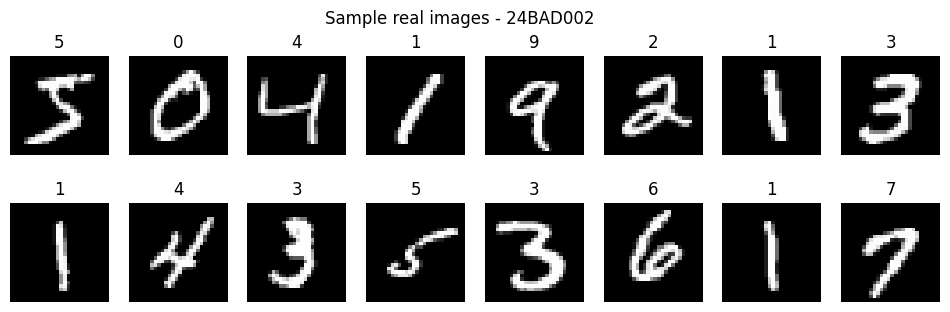

In [27]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(y_train[i])
    ax.axis("off")
fig.suptitle(f"Sample real images - {ROLL_NO}")
plt.show()

In [28]:
# normalize to [-1, 1] and add the channel dimension
train_images = (x_train.astype("float32") - 127.5) / 127.5
train_images = train_images.reshape(-1, 28, 28, 1)
print("Shape:", train_images.shape)
print("Min:", train_images.min(), "Max:", train_images.max())

Shape: (60000, 28, 28, 1)
Min: -1.0 Max: 1.0


In [29]:
BATCH_SIZE = 128

train_dataset = (tf.data.Dataset.from_tensor_slices(train_images)
                 .shuffle(len(train_images))
                 .batch(BATCH_SIZE, drop_remainder=True)
                 .prefetch(tf.data.AUTOTUNE))

batch = next(iter(train_dataset))
print("Batch shape:", batch.shape)
print("Batches per epoch:", len(train_dataset))

Batch shape: (128, 28, 28, 1)
Batches per epoch: 468


---
# PART B: IMPLEMENTING THE GENERATOR

In [30]:
LATENT_DIM = 100

generator = keras.Sequential([
    keras.Input(shape=(LATENT_DIM,)),
    layers.Dense(7 * 7 * 256, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(0.2),
    layers.Reshape((7, 7, 256)),
    layers.Conv2DTranspose(128, 5, strides=1, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh"),
], name="generator")

print("Roll No:", ROLL_NO)
generator.summary()

Roll No: 24BAD002


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

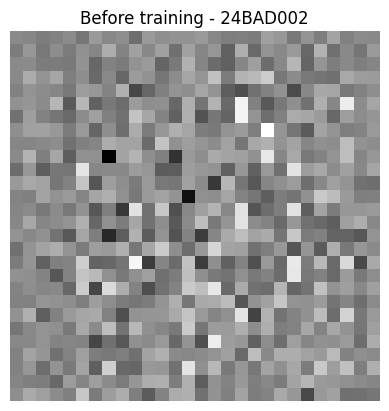

In [31]:
noise = tf.random.normal([1, LATENT_DIM])
img = generator(noise, training=False)

plt.imshow(img[0, :, :, 0], cmap="gray")
plt.title(f"Before training - {ROLL_NO}")
plt.axis("off")
plt.show()

---
# PART C: IMPLEMENTING THE DISCRIMINATOR AND GAN MODEL

In [32]:
discriminator = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(64, 5, strides=2, padding="same"),
    layers.LeakyReLU(0.2),
    layers.Dropout(0.3),
    layers.Conv2D(128, 5, strides=2, padding="same"),
    layers.LeakyReLU(0.2),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1, activation="sigmoid"),
], name="discriminator")

d_optimizer = keras.optimizers.Adam(2e-4, beta_1=0.5)
g_optimizer = keras.optimizers.Adam(2e-4, beta_1=0.5)
bce = keras.losses.BinaryCrossentropy()
discriminator.compile(optimizer=d_optimizer, loss=bce, metrics=["accuracy"])

# combined model: noise -> generator -> discriminator
# only the generator's weights are updated when training through it
gan = keras.Sequential([keras.Input(shape=(LATENT_DIM,)), generator, discriminator], name="gan")

print("Roll No:", ROLL_NO)
generator.summary()
discriminator.summary()
gan.summary()

Roll No: 24BAD002


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

...

Model: "gan"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ generator (Sequential)          │ (None, 28, 28, 1)      │     2,330,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ discriminator (Sequential)      │ (None, 1)              │       212,865 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,543,810 (9.70 MB)

 Trainable params: 2,518,338 (9.61 MB)

 Non-trainable params: 25,472 (99.50 KB)

---
# PART D: GAN TRAINING AND SYNTHETIC IMAGE GENERATION

In [33]:
EPOCHS = 40
REAL_LABEL = 0.9   # one-sided label smoothing
OUT_DIR = "generated_images"
os.makedirs(OUT_DIR, exist_ok=True)

seed_noise = tf.random.normal([16, LATENT_DIM])
snapshot_epochs = [1] + list(range(5, EPOCHS + 1, 5))

g_loss_m = keras.metrics.Mean()
d_loss_m = keras.metrics.Mean()

@tf.function
def train_step(real_images):
    n = tf.shape(real_images)[0]

    # train the discriminator on real and generated images
    fake_images = generator(tf.random.normal([n, LATENT_DIM]), training=True)
    with tf.GradientTape() as tape:
        real_out = discriminator(real_images, training=True)
        fake_out = discriminator(fake_images, training=True)
        d_loss = (bce(tf.ones_like(real_out) * REAL_LABEL, real_out)
                  + bce(tf.zeros_like(fake_out), fake_out))
    grads = tape.gradient(d_loss, discriminator.trainable_variables)
    d_optimizer.apply_gradients(zip(grads, discriminator.trainable_variables))

    # train the generator through the combined model
    with tf.GradientTape() as tape:
        preds = gan(tf.random.normal([n, LATENT_DIM]), training=True)
        g_loss = bce(tf.ones_like(preds), preds)
    grads = tape.gradient(g_loss, generator.trainable_variables)
    g_optimizer.apply_gradients(zip(grads, generator.trainable_variables))

    g_loss_m.update_state(g_loss)
    d_loss_m.update_state(d_loss)

def make_grid(images, rows, cols):
    images = (np.asarray(images)[..., 0] + 1) / 2
    return images.reshape(rows, cols, 28, 28).transpose(0, 2, 1, 3).reshape(rows * 28, cols * 28)

history = {"epoch": [], "g_loss": [], "d_loss": []}
snapshots = {0: generator(seed_noise, training=False).numpy()}

In [34]:
print("Roll No:", ROLL_NO)
for epoch in range(1, EPOCHS + 1):
    g_loss_m.reset_state()
    d_loss_m.reset_state()

    for image_batch in train_dataset:
        train_step(image_batch)

    history["epoch"].append(epoch)
    history["g_loss"].append(float(g_loss_m.result()))
    history["d_loss"].append(float(d_loss_m.result()))
    print(f"Epoch {epoch}/{EPOCHS}  G loss: {history['g_loss'][-1]:.4f}  D loss: {history['d_loss'][-1]:.4f}")

    if epoch in snapshot_epochs:
        snapshots[epoch] = generator(seed_noise, training=False).numpy()
        plt.imsave(f"{OUT_DIR}/epoch_{epoch:03d}.png", make_grid(snapshots[epoch], 4, 4), cmap="gray")

Roll No: 24BAD002
Epoch 1/40  G loss: 0.8483  D loss: 1.3317
Epoch 2/40  G loss: 0.9148  D loss: 1.3152
Epoch 3/40  G loss: 0.8846  D loss: 1.3421
Epoch 4/40  G loss: 0.8595  D loss: 1.3460
Epoch 5/40  G loss: 0.8679  D loss: 1.3436
Epoch 6/40  G loss: 0.8821  D loss: 1.3372
Epoch 7/40  G loss: 0.8850  D loss: 1.3315
Epoch 8/40  G loss: 0.8963  D loss: 1.3285
Epoch 9/40  G loss: 0.9001  D loss: 1.3225
Epoch 10/40  G loss: 0.9097  D loss: 1.3227
Epoch 11/40  G loss: 0.9056  D loss: 1.3173
Epoch 12/40  G loss: 0.9130  D loss: 1.3181
Epoch 13/40  G loss: 0.9148  D loss: 1.3177
Epoch 14/40  G loss: 0.9044  D loss: 1.3179
Epoch 15/40  G loss: 0.9127  D loss: 1.3182
Epoch 16/40  G loss: 0.9097  D loss: 1.3166
Epoch 17/40  G loss: 0.9166  D loss: 1.3190
Epoch 18/40  G loss: 0.9100  D loss: 1.3169
Epoch 19/40  G loss: 0.9171  D loss: 1.3211
Epoch 20/40  G loss: 0.9053  D loss: 1.3184
Epoch 21/40  G loss: 0.9123  D loss: 1.3215
Epoch 22/40  G loss: 0.9039  D loss: 1.3202
Epoch 23/40  G loss: 0.

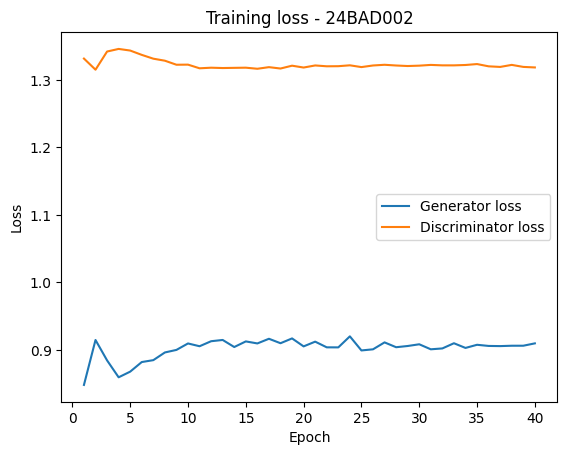

In [35]:
hist_df = pd.DataFrame(history)
hist_df.to_csv(f"{OUT_DIR}/training_history.csv", index=False)

plt.plot(hist_df.epoch, hist_df.g_loss, label="Generator loss")
plt.plot(hist_df.epoch, hist_df.d_loss, label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Training loss - {ROLL_NO}")
plt.legend()
plt.savefig(f"{OUT_DIR}/loss_curves.png")
plt.show()

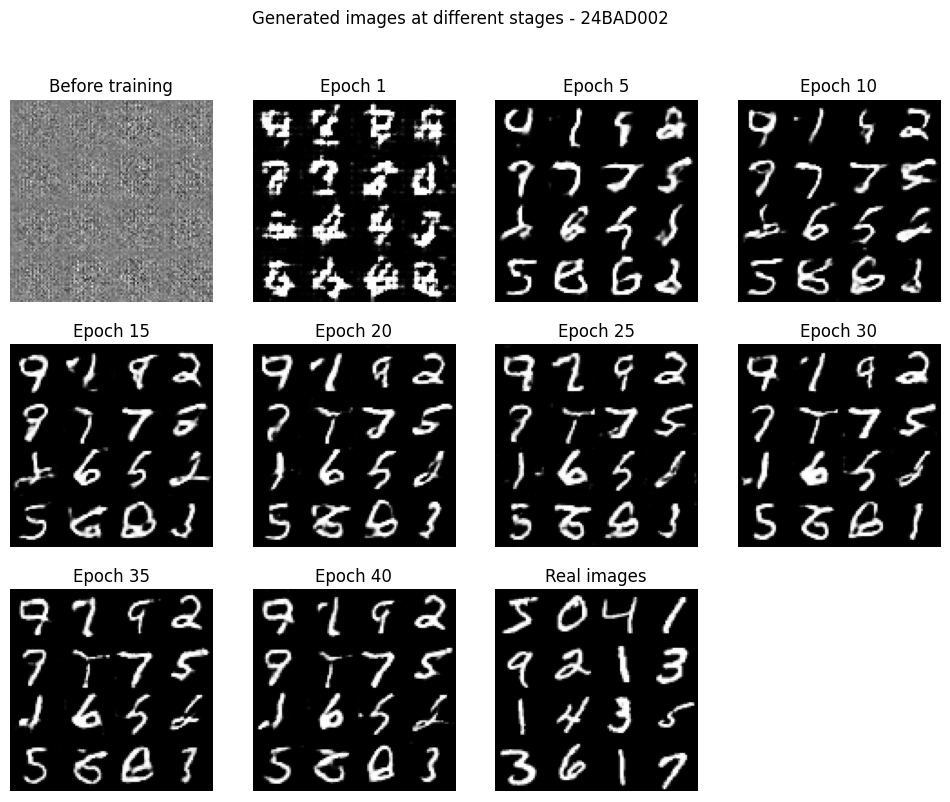

In [36]:
stages = sorted(snapshots)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, ep in zip(axes.ravel(), stages):
    ax.imshow(make_grid(snapshots[ep], 4, 4), cmap="gray")
    ax.set_title("Before training" if ep == 0 else f"Epoch {ep}")
for ax in axes.ravel():
    ax.axis("off")
axes.ravel()[len(stages)].imshow(make_grid(train_images[:16], 4, 4), cmap="gray")
axes.ravel()[len(stages)].set_title("Real images")
fig.suptitle(f"Generated images at different stages - {ROLL_NO}")
plt.savefig(f"{OUT_DIR}/training_progress.png")
plt.show()

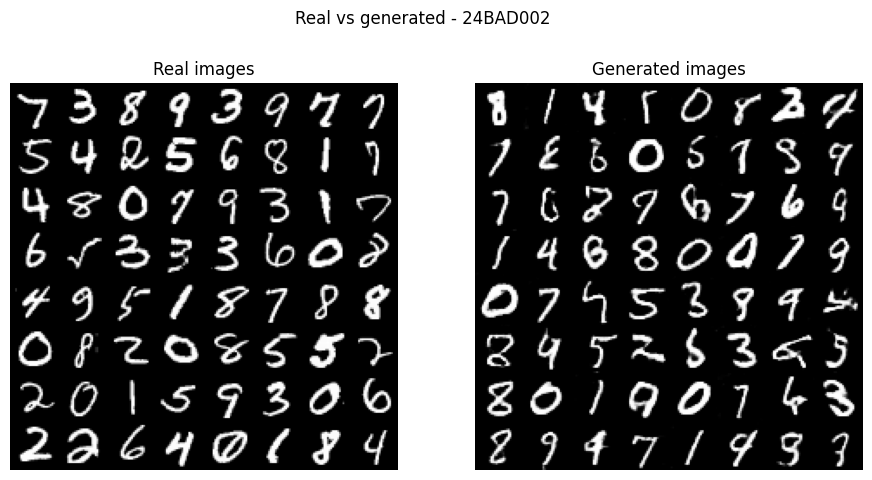

In [37]:
final_fake = generator(tf.random.normal([64, LATENT_DIM]), training=False).numpy()
real_sample = train_images[np.random.choice(len(train_images), 64, replace=False)]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(make_grid(real_sample, 8, 8), cmap="gray")
axes[0].set_title("Real images")
axes[1].imshow(make_grid(final_fake, 8, 8), cmap="gray")
axes[1].set_title("Generated images")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Real vs generated - {ROLL_NO}")
plt.savefig(f"{OUT_DIR}/real_vs_generated.png")
plt.show()

Classifier accuracy on real test images: 0.9833
                              Real  Generated
Mean pixel value            -0.758     -0.741
Pixel std                    0.593      0.611
Mean classifier confidence   0.970      0.896
Digit classes produced      10.000     10.000


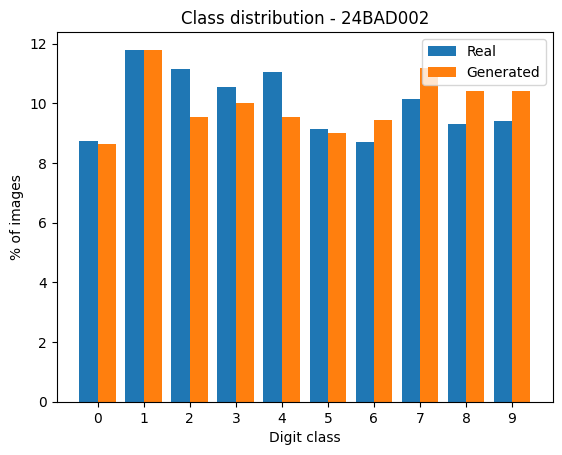

In [38]:
# a small classifier trained on real digits is used to judge the generated images
clf = keras.Sequential([
    keras.Input((28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dropout(0.3), layers.Dense(10, activation="softmax"),
])
clf.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
clf.fit(train_images, y_train, epochs=2, batch_size=256, verbose=0)

x_test_n = ((x_test.astype("float32") - 127.5) / 127.5).reshape(-1, 28, 28, 1)
print("Classifier accuracy on real test images:", round(clf.evaluate(x_test_n, y_test, verbose=0)[1], 4))

N = 2000
gen_eval = generator(tf.random.normal([N, LATENT_DIM]), training=False).numpy()
gen_probs = clf.predict(gen_eval, batch_size=500, verbose=0)
real_probs = clf.predict(x_test_n[:N], batch_size=500, verbose=0)

summary = pd.DataFrame({
    "Real": [x_test_n[:N].mean(), x_test_n[:N].std(), real_probs.max(1).mean(), len(np.unique(real_probs.argmax(1)))],
    "Generated": [gen_eval.mean(), gen_eval.std(), gen_probs.max(1).mean(), len(np.unique(gen_probs.argmax(1)))],
}, index=["Mean pixel value", "Pixel std", "Mean classifier confidence", "Digit classes produced"]).round(3)
print(summary)

width = 0.4
x = np.arange(10)
plt.bar(x - width / 2, np.bincount(real_probs.argmax(1), minlength=10) / N * 100, width, label="Real")
plt.bar(x + width / 2, np.bincount(gen_probs.argmax(1), minlength=10) / N * 100, width, label="Generated")
plt.xticks(x)
plt.xlabel("Digit class")
plt.ylabel("% of images")
plt.title(f"Class distribution - {ROLL_NO}")
plt.legend()
plt.savefig(f"{OUT_DIR}/class_distribution.png")
plt.show()

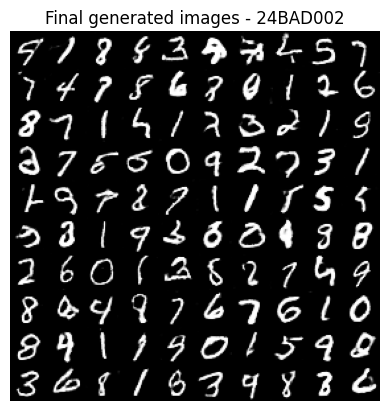

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
os.makedirs(f"{OUT_DIR}/final", exist_ok=True)
for i in range(100):
    plt.imsave(f"{OUT_DIR}/final/gen_{i:03d}.png", (gen_eval[i, :, :, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)

plt.imsave(f"{OUT_DIR}/final_grid.png", make_grid(gen_eval[:100], 10, 10), cmap="gray")
np.save(f"{OUT_DIR}/final_generated_images.npy", gen_eval)
generator.save(f"{OUT_DIR}/generator_final.keras")
shutil.make_archive("generated_images", "zip", OUT_DIR)

plt.imshow(make_grid(gen_eval[:100], 10, 10), cmap="gray")
plt.title(f"Final generated images - {ROLL_NO}")
plt.axis("off")
plt.show()

try:
    from google.colab import files
    files.download("generated_images.zip")
except ImportError:
    pass